100%|██████████| 26.4M/26.4M [00:01<00:00, 21.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 338kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.17MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.9MB/s]


Starting Adversarial Training Loop...
Epoch [1/5] | Loss D: 0.0000 | Loss G: 10.8619
Epoch [2/5] | Loss D: 0.0000 | Loss G: 17.3047
Epoch [3/5] | Loss D: 0.0000 | Loss G: 21.3368
Epoch [4/5] | Loss D: 0.0000 | Loss G: 21.4624
Epoch [5/5] | Loss D: 0.0000 | Loss G: 24.4203


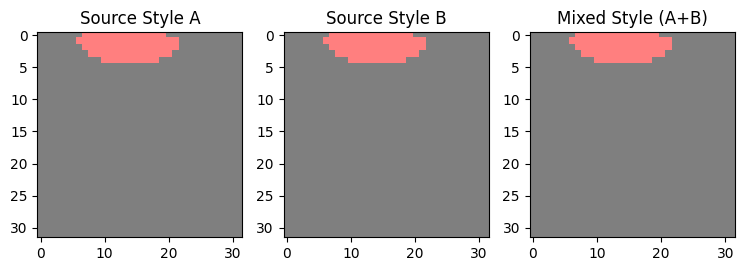

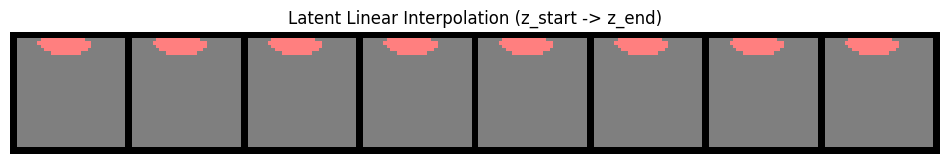

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================
# 1. Dataset Loading and Normalization
# ==========================================
# Load Fashion-MNIST, resize to 32x32, repeat to 3 channels, normalize to [-1, 1]
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)), # Maps [0,1] to [-1,1]
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)) # 1 channel to 3 channels
])

train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True, drop_last=True)

# ==========================================
# 2. Mapping Network
# ==========================================
class MappingNetwork(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        layers = []
        for i in range(8):
            layers.append(nn.Linear(latent_dim, latent_dim))
            layers.append(nn.ReLU())
        self.mapping = nn.Sequential(*layers)

    def forward(self, z):
        # Normalize input z (PixelNorm equivalent for simplicity)
        z = z / torch.sqrt(torch.mean(z ** 2, dim=-1, keepdim=True) + 1e-8)
        return self.mapping(z)

# ==========================================
# 3. Synthesis Network with AdaIN
# ==========================================
class AdaIN(nn.Module):
    def __init__(self, channels, latent_dim=128):
        super().__init__()
        self.instance_norm = nn.InstanceNorm2d(channels, affine=False)
        self.linear = nn.Linear(latent_dim, channels * 2)

    def forward(self, x, w):
        # Generate scale (ys) and bias (yb) from style w
        style = self.linear(w).unsqueeze(2).unsqueeze(3)
        ys, yb = style.chunk(2, dim=1)
        return self.instance_norm(x) * (ys + 1) + yb  # +1 to center scale around 1

class SynthesisBlock(nn.Module):
    def __init__(self, in_channels, out_channels, latent_dim=128, upsample=True):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False) if upsample else None
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.adain = AdaIN(out_channels, latent_dim)
        self.relu = nn.ReLU()

    def forward(self, x, w):
        if self.upsample:
            x = self.upsample(x)
        x = self.conv(x)
        x = self.adain(x, w)
        return self.relu(x)

class SynthesisNetwork(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        # Learned constant tensor initialized at 4x4 resolution
        self.learned_constant = nn.Parameter(torch.randn(1, 128, 4, 4))

        # Resolution blocks: 4x4 -> 8x8 -> 16x16 -> 32x32
        self.block1 = SynthesisBlock(128, 128, latent_dim, upsample=False) # 4x4
        self.block2 = SynthesisBlock(128, 64, latent_dim, upsample=True)   # 8x8
        self.block3 = SynthesisBlock(64, 32, latent_dim, upsample=True)    # 16x16
        self.block4 = SynthesisBlock(32, 3, latent_dim, upsample=True)     # 32x32 (RGB output)

    def forward(self, w_list):
        # Expects a list/tuple of w vectors for style mixing injection points
        x = self.learned_constant.repeat(w_list[0].shape[0], 1, 1, 1)

        x = self.block1(x, w_list[0])
        x = self.block2(x, w_list[1])
        x = self.block3(x, w_list[2])
        x = self.block4(x, w_list[3])
        return torch.tanh(x) # Scale output to [-1, 1]

class Generator(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.mapping = MappingNetwork(latent_dim)
        self.synthesis = SynthesisNetwork(latent_dim)

    def forward(self, z, style_mixing_step=None, z_mix=None):
        if style_mixing_step is not None and z_mix is not None:
            w1 = self.mapping(z)
            w2 = self.mapping(z_mix)
            # Inject w1 into early layers, w2 into late layers
            w_list = [w1 if i < style_mixing_step else w2 for i in range(4)]
        else:
            w = self.mapping(z)
            w_list = [w] * 4

        return self.synthesis(w_list)

# ==========================================
# 4. Standard Convolutional Discriminator
# ==========================================
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # Input: 3 x 32 x 32
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            # 32 x 16 x 16
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            # 64 x 8 x 8
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            # 128 x 4 x 4
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 1)
        )

    def forward(self, x):
        return self.net(x)

# Initialize Models
latent_dim = 128
netG = Generator(latent_dim).to(device)
netD = Discriminator().to(device)

optG = optim.Adam(netG.parameters(), lr=0.0002, betas=(0.0, 0.99))
optD = optim.Adam(netD.parameters(), lr=0.0002, betas=(0.0, 0.99))

# 5. Adversarial Training (Non-saturating GAN Loss)
epochs = 5 # Small number for demonstration
criterion = nn.BCEWithLogitsLoss()

print("Starting Adversarial Training Loop...")
for epoch in range(epochs):
    for i, (real_imgs, _) in enumerate(train_loader):
        batch_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)

        # ---------------------
        # Train Discriminator
        # ---------------------
        optD.zero_grad()
        z = torch.randn(batch_size, latent_dim).to(device)
        fake_imgs = netG(z)

        d_real = netD(real_imgs)
        d_fake = netD(fake_imgs.detach())

        # Non-saturating loss components for D
        loss_D_real = criterion(d_real, torch.ones_like(d_real))
        loss_D_fake = criterion(d_fake, torch.zeros_like(d_fake))
        loss_D = loss_D_real + loss_D_fake
        loss_D.backward()
        optD.step()

        # ---------------------
        # Train Generator
        # ---------------------
        optG.zero_grad()
        d_fake_for_G = netD(fake_imgs)

        # Non-saturating loss for G: maximize log(D(G(z)))
        loss_G = criterion(d_fake_for_G, torch.ones_like(d_fake_for_G))
        loss_G.backward()
        optG.step()

    print(f"Epoch [{epoch+1}/{epochs}] | Loss D: {loss_D.item():.4f} | Loss G: {loss_G.item():.4f}")

# Helper function to convert tensors to plottable format
def denorm_and_numpy(tensor):
    grid = torchvision.utils.make_grid(tensor, normalize=True, value_range=(-1, 1))
    return grid.permute(1, 2, 0).cpu().detach().numpy()

# 6. Style Mixing Verification
netG.eval()
with torch.no_grad():
    z1 = torch.randn(1, latent_dim).to(device)
    z2 = torch.randn(1, latent_dim).to(device)

    img_style1 = netG(z1)
    img_style2 = netG(z2)
    # Blend: Early layers (0, 1) use z1, late layers (2, 3) use z2
    img_mixed = netG(z1, style_mixing_step=2, z_mix=z2)

    plt.figure(figsize=(9, 3))
    plt.subplot(1, 3, 1); plt.imshow(denorm_and_numpy(img_style1)); plt.title("Source Style A")
    plt.subplot(1, 3, 2); plt.imshow(denorm_and_numpy(img_style2)); plt.title("Source Style B")
    plt.subplot(1, 3, 3); plt.imshow(denorm_and_numpy(img_mixed)); plt.title("Mixed Style (A+B)")
    plt.show()

# 7. Latent Interpolation Verification
with torch.no_grad():
    z_start = torch.randn(1, latent_dim).to(device)
    z_end = torch.randn(1, latent_dim).to(device)

    steps = 8
    interpolation_imgs = []
    for alpha in np.linspace(0, 1, steps):
        z_interp = (1 - alpha) * z_start + alpha * z_end
        img_interp = netG(z_interp)
        interpolation_imgs.append(img_interp.squeeze(0))

    grid_tensor = torch.stack(interpolation_imgs)
    plt.figure(figsize=(12, 4))
    plt.imshow(denorm_and_numpy(grid_tensor))
    plt.title("Latent Linear Interpolation (z_start -> z_end)")
    plt.axis('off')
    plt.show()
